# Power Curve Analysis
## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Reading in the Datasets

In [2]:
# load in turbine and met masts datasets
scada = pd.read_parquet('../../data/cleaned/scada_data.parquet')
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')

## Generating Power Curves

In [7]:
def corrected_wind_speed(wind_speed, air_density, ws0 = 7, ws1 = 12, ex0 = 1/3, ex1 = 2/3, standard = 1.13):
    frac = np.clip((wind_speed - ws0) / (ws1 - ws0), 0, 1)
    exponent = ex0 + frac * (ex1 - ex0)
    
    return wind_speed * (air_density / standard) ** exponent

In [8]:
scada['corrected_ws'] = corrected_wind_speed(scada['wind_speed'], scada['air_density'])

In [97]:
def avg_power_curve(df_full, turbine, p, cutin, rated, width):
    # defining dataframe based on turbine
    df = df_full[(df_full['turbine'] == turbine) & (df_full['wind_speed'] >= cutin) & (df_full['wind_speed'] <= rated)].copy()
    df['period'] = df['utc'].dt.to_period(p)

    # defining the bins within the dataset
    n_bins = int(np.ceil((rated - cutin) / width))
    df['bin'] = ((df['wind_speed'] - cutin) // width).astype('Int64').clip(upper = n_bins - 1)

    # defining the means within each bin for real power and theoretical power
    bin_means = (df.groupby(['period', 'bin']).agg(mean_real_power = ('KPI_real_power_ac', 'mean'),
                                                   mean_theoretical_power = ('KPI_theoretical_power', 'mean'),
                                                   n = ('KPI_real_power_ac', 'count')).reset_index())

    # creating variables of interest in the dataframe
    bin_means['wind_speed'] = cutin + bin_means['bin'] * width + width / 2
    bin_means['turbine'] = turbine
    bin_means['perc_diff'] = np.where(bin_means['mean_theoretical_power'] == 0, 0, 
                                      (bin_means['mean_real_power'] - bin_means['mean_theoretical_power']) / bin_means['mean_theoretical_power'])
    bin_means['avg_perc_diff'] = bin_means.groupby('period')['perc_diff'].transform('mean')

    return bin_means

In [98]:
result = avg_power_curve(scada, 'WTG157', p = 'M', cutin = 3, rated = 15, width = 0.5)

In [105]:
result[result['period'] == '2026-01']

,period,bin,mean_real_power,mean_theoretical_power,n,wind_speed,turbine,perc_diff,avg_perc_diff
0,2026-01,0,0.645228,0.087130,676,3.25,WTG157,6.405352,0.15267
1,2026-01,1,7.080973,10.868567,660,3.75,WTG157,-0.348491,0.15267
2,2026-01,2,28.553616,96.351401,516,4.25,WTG157,-0.703651,0.15267
3,2026-01,3,87.912179,175.945922,306,4.75,WTG157,-0.500345,0.15267
4,2026-01,4,171.395860,261.605226,172,5.25,WTG157,-0.344830,0.15267
5,2026-01,5,254.426107,358.873957,89,5.75,WTG157,-0.291043,0.15267
6,2026-01,6,365.104147,456.218241,59,6.25,WTG157,-0.199716,0.15267
7,2026-01,7,467.274982,626.061491,48,6.75,WTG157,-0.253628,0.15267
8,2026-01,8,609.842459,700.585387,52,7.25,WTG157,-0.129524,0.15267
9,2026-01,9,829.749352,866.879073,37,7.75,WTG157,-0.042831,0.15267


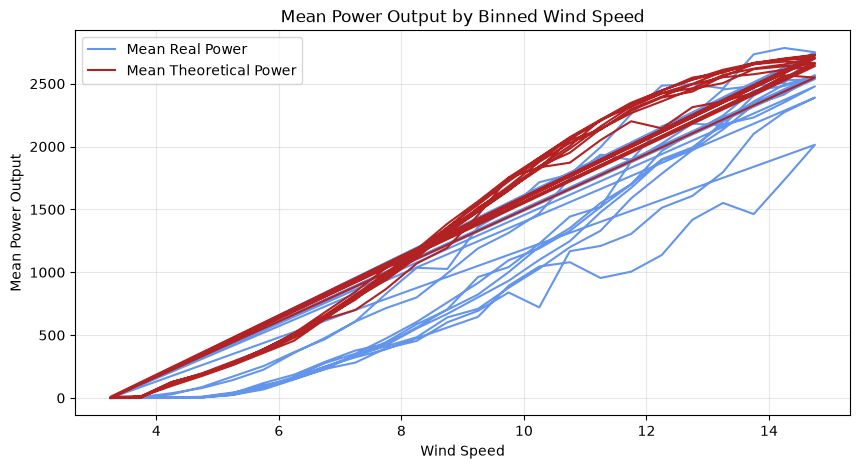

In [88]:
plt.figure(figsize = (10, 5))
plt.plot(result['wind_speed'], result['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
plt.plot(result['wind_speed'], result['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
plt.legend()
plt.xlabel('Wind Speed')
plt.ylabel('Mean Power Output')
plt.title('Mean Power Output by Binned Wind Speed')
plt.grid(alpha = 0.3)
plt.show()

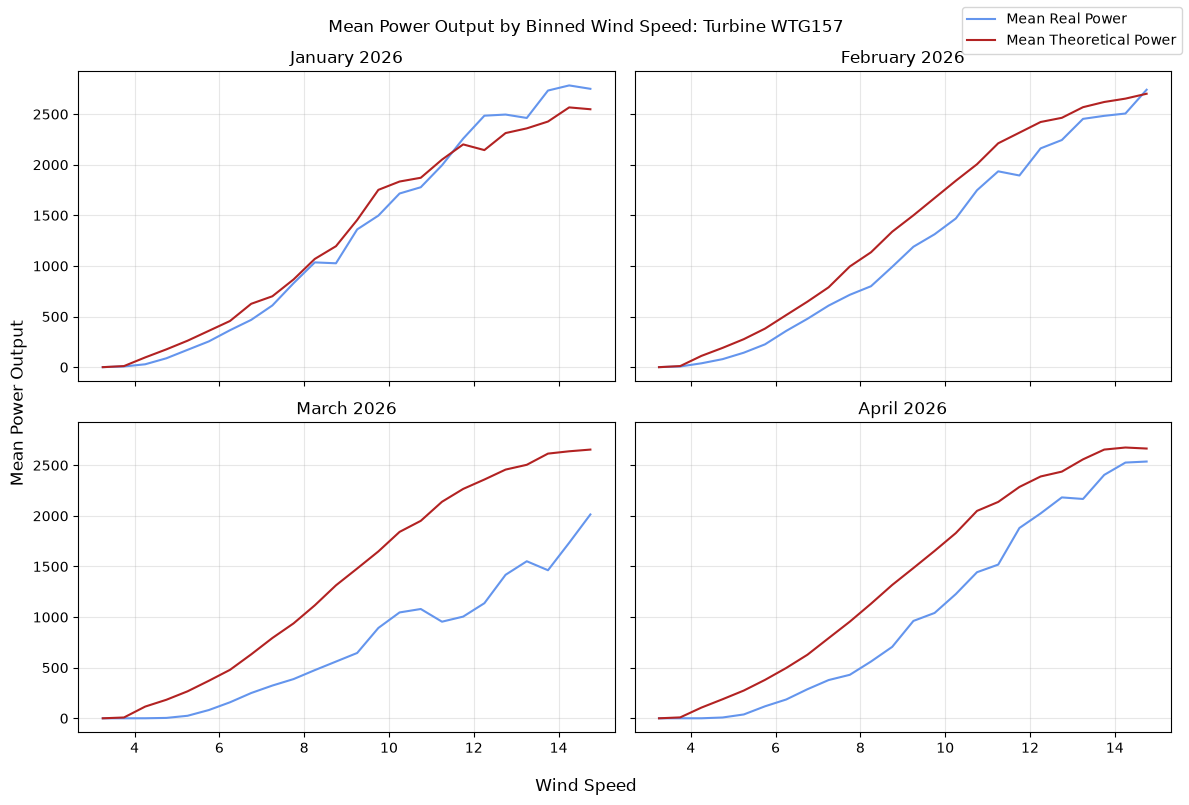

In [89]:
months = result['period'].unique()[:4]

fig, axes = plt.subplots(2, 2, figsize = (12, 8), sharex = True, sharey = True)

for ax, month in zip(axes.flat, months):
    grp = result[result['period'] == month]
    ax.plot(grp['wind_speed'], grp['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
    ax.plot(grp['wind_speed'], grp['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
    ax.set_title(month.strftime('%B %Y'))
    ax.grid(alpha = 0.3)

fig.supxlabel('Wind Speed')
fig.supylabel('Mean Power Output')
fig.suptitle('Mean Power Output by Binned Wind Speed: Turbine WTG157')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper right')

plt.tight_layout()
plt.show()